# CFRP-CFRP Lap-Shear Strength

## Imports

In [1]:
import os
import json
import time
import pickle
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GroupKFold, KFold, GridSearchCV, train_test_split, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor, ExtraTreesClassifier,
                              GradientBoostingRegressor, GradientBoostingClassifier, AdaBoostRegressor, AdaBoostClassifier)
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.gaussian_process import GaussianProcessRegressor, GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, Matern, WhiteKernel, ConstantKernel as C

warnings.filterwarnings('ignore')
sns.set_theme(style='ticks', context='notebook')

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

In [2]:
TASK = 'CFRP_CFRP__LSS'
FOLDER = 'CFRP_CFRP'
SEED = 42
SCORING = 'r2'
RESULTS = '../results'
os.makedirs(f'{RESULTS}/models', exist_ok=True)

## Data

In [3]:
df = pd.read_csv(f'../data/processed/{FOLDER}/{TASK}.csv')
df.head()

,Row_ID,Paper_ID,Value_Type,Target_Is_Derived,No_Plies,Adherend1_Thickness_mm,Adherend2_Thickness_mm,Adherend1_Modulus_GPa,Adherend2_Modulus_GPa,Adherend1_Strength_MPa,...,Surf_Peel_ply,Surf_Plasma_corona,Surf_UV_ozone,Surf_Laser,Surf_Chemical_electrochemical,Surf_Other_modifier,Surf_None_as_received,Surf_Ultrasonic_vibration_assisted,Surf_Unknown,LSS_MPa
0,21,2,Lower,0,16.0,2.40,2.40,111.0,111.0,1690.0,...,0,0,0,0,0,0,0,0,0,16.25
1,22,2,Mean,0,16.0,2.40,2.40,111.0,111.0,1690.0,...,0,0,0,0,0,0,0,0,0,17.00
2,23,2,Upper,0,16.0,2.40,2.40,111.0,111.0,1690.0,...,0,0,0,0,0,0,0,0,0,17.82
3,27,4,Single,0,NaN,2.48,2.48,67.6,67.6,885.0,...,1,0,0,0,0,0,0,0,0,11.90
4,28,4,Single,0,NaN,2.48,2.48,67.6,67.6,885.0,...,1,0,0,0,0,0,0,0,0,12.80


In [4]:
print(df.shape, df['Paper_ID'].nunique())
df.describe().T

(676, 51) 28


,count,mean,std,min,25%,50%,75%,max
Row_ID,676.0,680.337278,344.571208,21.0000,394.75000,591.5000,1005.2500,1257.000000
Paper_ID,676.0,39.233728,17.654003,2.0000,25.00000,30.0000,57.0000,68.000000
Target_Is_Derived,676.0,0.380178,0.485790,0.0000,0.00000,0.0000,1.0000,1.000000
No_Plies,486.0,9.806584,4.124810,2.0000,7.00000,9.0000,12.0000,32.000000
Adherend1_Thickness_mm,661.0,2.165492,0.484190,1.4800,2.00000,2.2500,2.5000,3.200000
Adherend2_Thickness_mm,661.0,2.165492,0.484190,1.4800,2.00000,2.2500,2.5000,3.200000
Adherend1_Modulus_GPa,436.0,81.101995,33.695401,55.0000,71.50000,72.0000,72.0000,230.000000
Adherend2_Modulus_GPa,436.0,81.101995,33.695401,55.0000,71.50000,72.0000,72.0000,230.000000
Adherend1_Strength_MPa,278.0,806.835971,430.954051,622.0000,650.00000,650.0000,678.0000,2180.000000
Adherend2_Strength_MPa,278.0,806.835971,430.954051,622.0000,650.00000,650.0000,678.0000,2180.000000


## Train-Test Split

In [5]:
meta_cols = ['Row_ID', 'Paper_ID', 'Value_Type', 'Target_Is_Derived']
target = df.columns[-1]

X = df.drop(columns=meta_cols + [target])
y = df[target]
groups = df['Paper_ID'].values

idx = np.arange(len(df))
train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=SEED)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print(len(train_idx), len(test_idx), len(set(groups[train_idx])), 'studies in the training part')

540 136 28 studies in the training part


## Helper Functions

In [6]:
FAMILY = {'OLS': 'Linear', 'Ridge': 'Linear', 'Lasso': 'Linear', 'ElasticNet': 'Linear', 'LogReg-L2': 'Linear', 'LogReg-L1': 'Linear',
          'SVR': 'Kernel', 'SVC': 'Kernel', 'MLP': 'Neural net', 'DT': 'Tree', 'RF': 'Forest', 'ET': 'Forest',
          'GB': 'Boosting', 'XGB': 'Boosting', 'LGBM': 'Boosting', 'AB': 'Boosting', 'CatBoost': 'Boosting',
          'KNN': 'Nearest neighbour', 'BayesRidge': 'Bayesian', 'GPR': 'Bayesian', 'GPC': 'Bayesian', 'GNB': 'Bayesian'}


def make_pipeline(model, impute=True, scale_target=False):
    # median imputation (fitted on the training data), MinMax scaling to [0, 1], then the model
    if scale_target and not False:
        model = TransformedTargetRegressor(regressor=model, transformer=StandardScaler())
    steps = [('imputer', SimpleImputer(strategy='median'))] if impute else []
    return Pipeline(steps + [('scaler', MinMaxScaler()), ('model', model)])


def get_scores(y_true, y_pred):
    if False:
        return dict(acc=accuracy_score(y_true, y_pred), f1=f1_score(y_true, y_pred, average='macro'))
    return dict(r2=r2_score(y_true, y_pred), mae=mean_absolute_error(y_true, y_pred), mse=mean_squared_error(y_true, y_pred))

In [7]:
results = []
predictions = {}
fitted = {}
KEY = 'r2'


def evaluate(name, model, param_grid, impute=True, scale_target=False):
    start = time.time()
    prefix = 'model__regressor__' if (scale_target and not False) else 'model__'
    n_splits = min(5, len(set(groups[train_idx])))

    # Step 1: grid search on the training part, folds grouped by study
    grid = GridSearchCV(make_pipeline(model, impute, scale_target), {prefix + k: v for k, v in param_grid.items()},
                        cv=GroupKFold(n_splits), scoring=SCORING, n_jobs=2, refit=False, error_score=np.nan)
    grid.fit(X_train, y_train, groups=groups[train_idx])
    best_params = {k[len(prefix):]: v for k, v in grid.best_params_.items()}
    build = lambda: make_pipeline(clone(model).set_params(**best_params), impute, scale_target)

    # Step 2: refit on the whole training part and score both parts
    t0 = time.perf_counter()
    best = build().fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred_test = best.predict(X_test)
    pred_time = (time.perf_counter() - t0) / len(test_idx) * 1000
    pred_train = best.predict(X_train)
    train_scores = get_scores(y_train, pred_train)
    test_scores = get_scores(y_test, pred_test)

    # Step 3: random 5-fold on the training part (leakage diagnostic) and study-grouped out-of-fold predictions
    random_cv = cross_val_predict(build(), X_train, y_train, cv=KFold(5, shuffle=True, random_state=0))
    oof = cross_val_predict(build(), X_train, y_train, cv=GroupKFold(n_splits), groups=groups[train_idx])

    # Step 4: five further random 80:20 splits with the tuned settings
    seeds = []
    for s in range(5):
        a, b = train_test_split(idx, test_size=0.2, random_state=s)
        p = build().fit(X.iloc[a], y.iloc[a]).predict(X.iloc[b])
        seeds.append(get_scores(y.iloc[b], p)[KEY])

    proba = None
    if False and hasattr(best, 'predict_proba'):
        try:
            proba = best.predict_proba(X_test)
        except Exception:
            proba = None

    fitted[name] = best
    predictions[name] = dict(train_idx=train_idx, test_idx=test_idx, y_train=y_train.values, y_test=y_test.values,
                             pred_train=pred_train, pred_test=pred_test, oof=oof, random_cv=random_cv, proba=proba)
    joblib.dump(best, f'{RESULTS}/models/{TASK}__{name}.joblib')
    row = dict(File=TASK, Target=target, Family=FAMILY[name], Model=name, Rows=len(df), Papers=len(set(groups)),
               Best_params=json.dumps({k: str(v) for k, v in best_params.items()}),
               GroupCV_tuned=round(grid.best_score_, 4),
               GroupOOF_score=round(get_scores(y_train, oof)[KEY], 4),
               Random5fold_score=round(get_scores(y_train, random_cv)[KEY], 4))
    row.update({f'Train_{k}': round(v, 4) for k, v in train_scores.items()})
    row.update({f'Test_{k}': round(v, 4) for k, v in test_scores.items()})
    row.update(Test5seeds_mean=round(float(np.mean(seeds)), 4), Test5seeds_sd=round(float(np.std(seeds)), 4),
               Fit_s=round(fit_time, 3), Pred_ms_per_row=round(pred_time, 4))
    results.append(row)
    print(name, f'test {KEY} = {test_scores[KEY]:.3f}', f'group CV = {grid.best_score_:.3f}', f'{time.time() - start:.0f}s')

## Linear Regression (OLS)

In [8]:
model = LinearRegression()
param_grid = {'fit_intercept': [True]}
evaluate('OLS', model, param_grid)

OLS test r2 = 0.728 group CV = -22.421 2s


## Ridge

In [9]:
model = Ridge()
param_grid = {'alpha': [0.01, 0.1, 1, 10, 100]}
evaluate('Ridge', model, param_grid)

Ridge test r2 = 0.444 group CV = -7.076 0s


## Lasso

In [10]:
model = Lasso(max_iter=50000)
param_grid = {'alpha': [1e-4, 1e-3, 1e-2, 1e-1]}
evaluate('Lasso', model, param_grid)

Lasso test r2 = 0.614 group CV = -11.570 0s


## ElasticNet

In [11]:
model = ElasticNet(max_iter=50000)
param_grid = {'alpha': [1e-3, 1e-2, 1e-1], 'l1_ratio': [0.2, 0.5, 0.8]}
evaluate('ElasticNet', model, param_grid)

ElasticNet test r2 = 0.525 group CV = -8.018 1s


## SVR

In [12]:
model = SVR(epsilon=0.05)
param_grid = {'C': [1, 10, 100], 'gamma': [0.01, 0.05, 0.2]}
evaluate('SVR', model, param_grid, scale_target=True)

SVR test r2 = 0.812 group CV = -7.451 1s


## MLP

In [13]:
model = MLPRegressor(max_iter=2000, early_stopping=True, random_state=0)
param_grid = {'hidden_layer_sizes': [(64,), (128, 64)], 'alpha': [1e-4, 1e-2]}
evaluate('MLP', model, param_grid, scale_target=True)

MLP test r2 = 0.850 group CV = -6.836 7s


## Decision Tree

In [14]:
model = DecisionTreeRegressor(random_state=0)
param_grid = {'max_depth': [6, 12, None], 'min_samples_leaf': [1, 3]}
evaluate('DT', model, param_grid)

DT test r2 = 0.902 group CV = -6.737 0s


## RF

In [15]:
model = RandomForestRegressor(random_state=0, n_jobs=1)
param_grid = {'n_estimators': [200, 400], 'max_depth': [None, 12], 'min_samples_leaf': [1, 2]}
evaluate('RF', model, param_grid)

RF test r2 = 0.910 group CV = -5.633 22s


## Extra Trees

In [16]:
model = ExtraTreesRegressor(random_state=0, n_jobs=1)
param_grid = {'n_estimators': [200, 400], 'max_depth': [None, 12], 'min_samples_leaf': [1, 2]}
evaluate('ET', model, param_grid)

ET test r2 = 0.899 group CV = -10.618 15s


## GB

In [17]:
model = GradientBoostingRegressor(random_state=0)
param_grid = {'n_estimators': [200, 400], 'max_depth': [3, 5]}
evaluate('GB', model, param_grid)

GB test r2 = 0.927 group CV = -3.839 6s


## XGB

In [18]:
model = xgb.XGBRegressor(random_state=0, n_jobs=1, subsample=0.8, colsample_bytree=0.8)
param_grid = {'n_estimators': [300, 600], 'max_depth': [4, 6], 'learning_rate': [0.05, 0.1]}
evaluate('XGB', model, param_grid, impute=False)

XGB test r2 = 0.903 group CV = -5.442 5s


## LGBM

In [19]:
model = lgb.LGBMRegressor(random_state=0, n_jobs=1, verbose=-1)
param_grid = {'n_estimators': [300, 600], 'num_leaves': [15, 31], 'learning_rate': [0.05, 0.1]}
evaluate('LGBM', model, param_grid, impute=False)

LGBM test r2 = 0.925 group CV = -5.417 4s


## Adaboost

In [20]:
model = AdaBoostRegressor(random_state=0)
param_grid = {'n_estimators': [100, 300], 'learning_rate': [0.1, 0.5, 1.0]}
evaluate('AB', model, param_grid)

AB test r2 = 0.742 group CV = -6.626 5s


## CatBoost

In [21]:
model = CatBoostRegressor(random_seed=0, verbose=0, thread_count=1, allow_writing_files=False)
param_grid = {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.05, 0.1]}
evaluate('CatBoost', model, param_grid, impute=False)

CatBoost test r2 = 0.924 group CV = -6.807 7s


## KNN

In [22]:
model = KNeighborsRegressor()
param_grid = {'n_neighbors': [3, 4, 5, 6, 7], 'weights': ['uniform', 'distance']}
evaluate('KNN', model, param_grid)

KNN test r2 = 0.866 group CV = -8.301 1s


## Bayesian Ridge

In [23]:
model = BayesianRidge()
param_grid = {'alpha_1': [1e-6, 1e-4], 'lambda_1': [1e-6, 1e-4]}
evaluate('BayesRidge', model, param_grid, scale_target=True)

BayesRidge test r2 = 0.709 group CV = -12.122 0s


## Gaussian Process

In [24]:
kernels = [C(1.0) * Matern(1.0, nu=1.5) + WhiteKernel(0.1),
           C(1.0) * Matern(1.0, nu=2.5) + WhiteKernel(0.1),
           C(1.0) * RBF(1.0) + WhiteKernel(0.1)]
model = GaussianProcessRegressor(normalize_y=True, n_restarts_optimizer=0, random_state=0)
param_grid = {'kernel': kernels}
evaluate('GPR', model, param_grid)

GPR test r2 = 0.884 group CV = -6.753 9s


## Results

In [25]:
results_df = pd.DataFrame(results)
results_df.to_csv(f'{RESULTS}/{TASK}__zoo_results.csv', index=False)
cols = ['Model', 'Family', 'Train_r2', 'Test_r2', 'Test5seeds_mean', 'Test5seeds_sd', 'GroupOOF_score', 'Test_mae']
results_df[cols].sort_values('Test_r2', ascending=False).reset_index(drop=True)

,Model,Family,Train_r2,Test_r2,Test5seeds_mean,Test5seeds_sd,GroupOOF_score,Test_mae
0,GB,Boosting,0.9027,0.9266,0.8410,0.0310,0.0350,1.5955
1,LGBM,Boosting,0.8997,0.9245,0.8538,0.0326,-0.2688,1.6402
2,CatBoost,Boosting,0.9121,0.9241,0.8423,0.0310,-0.2240,1.5101
3,RF,Forest,0.9124,0.9102,0.8313,0.0346,-0.1298,1.5931
4,XGB,Boosting,0.9117,0.9025,0.8164,0.0310,-0.1062,1.6483
5,DT,Tree,0.9113,0.9016,0.7918,0.0505,-0.3716,1.5342
6,ET,Forest,0.9100,0.8991,0.8184,0.0449,-0.4651,1.7355
7,GPR,Bayesian,0.8973,0.8844,0.8178,0.0628,-0.3506,1.8884
8,KNN,Nearest neighbour,0.9162,0.8660,0.7810,0.0729,-0.6025,1.7524
9,MLP,Neural net,0.8465,0.8504,0.7379,0.0522,-0.4059,2.2321


## Model Families

In [26]:
results_df.groupby('Family')['Test_r2'].agg(['mean', 'max', 'count']).sort_values('mean', ascending=False)

,mean,max,count
Family,,,
Forest,0.904650,0.9102,2
Tree,0.901600,0.9016,1
Boosting,0.883980,0.9266,5
Nearest neighbour,0.866000,0.8660,1
Neural net,0.850400,0.8504,1
Kernel,0.811600,0.8116,1
Bayesian,0.796850,0.8844,2
Linear,0.577725,0.7282,4


## Parity Plots

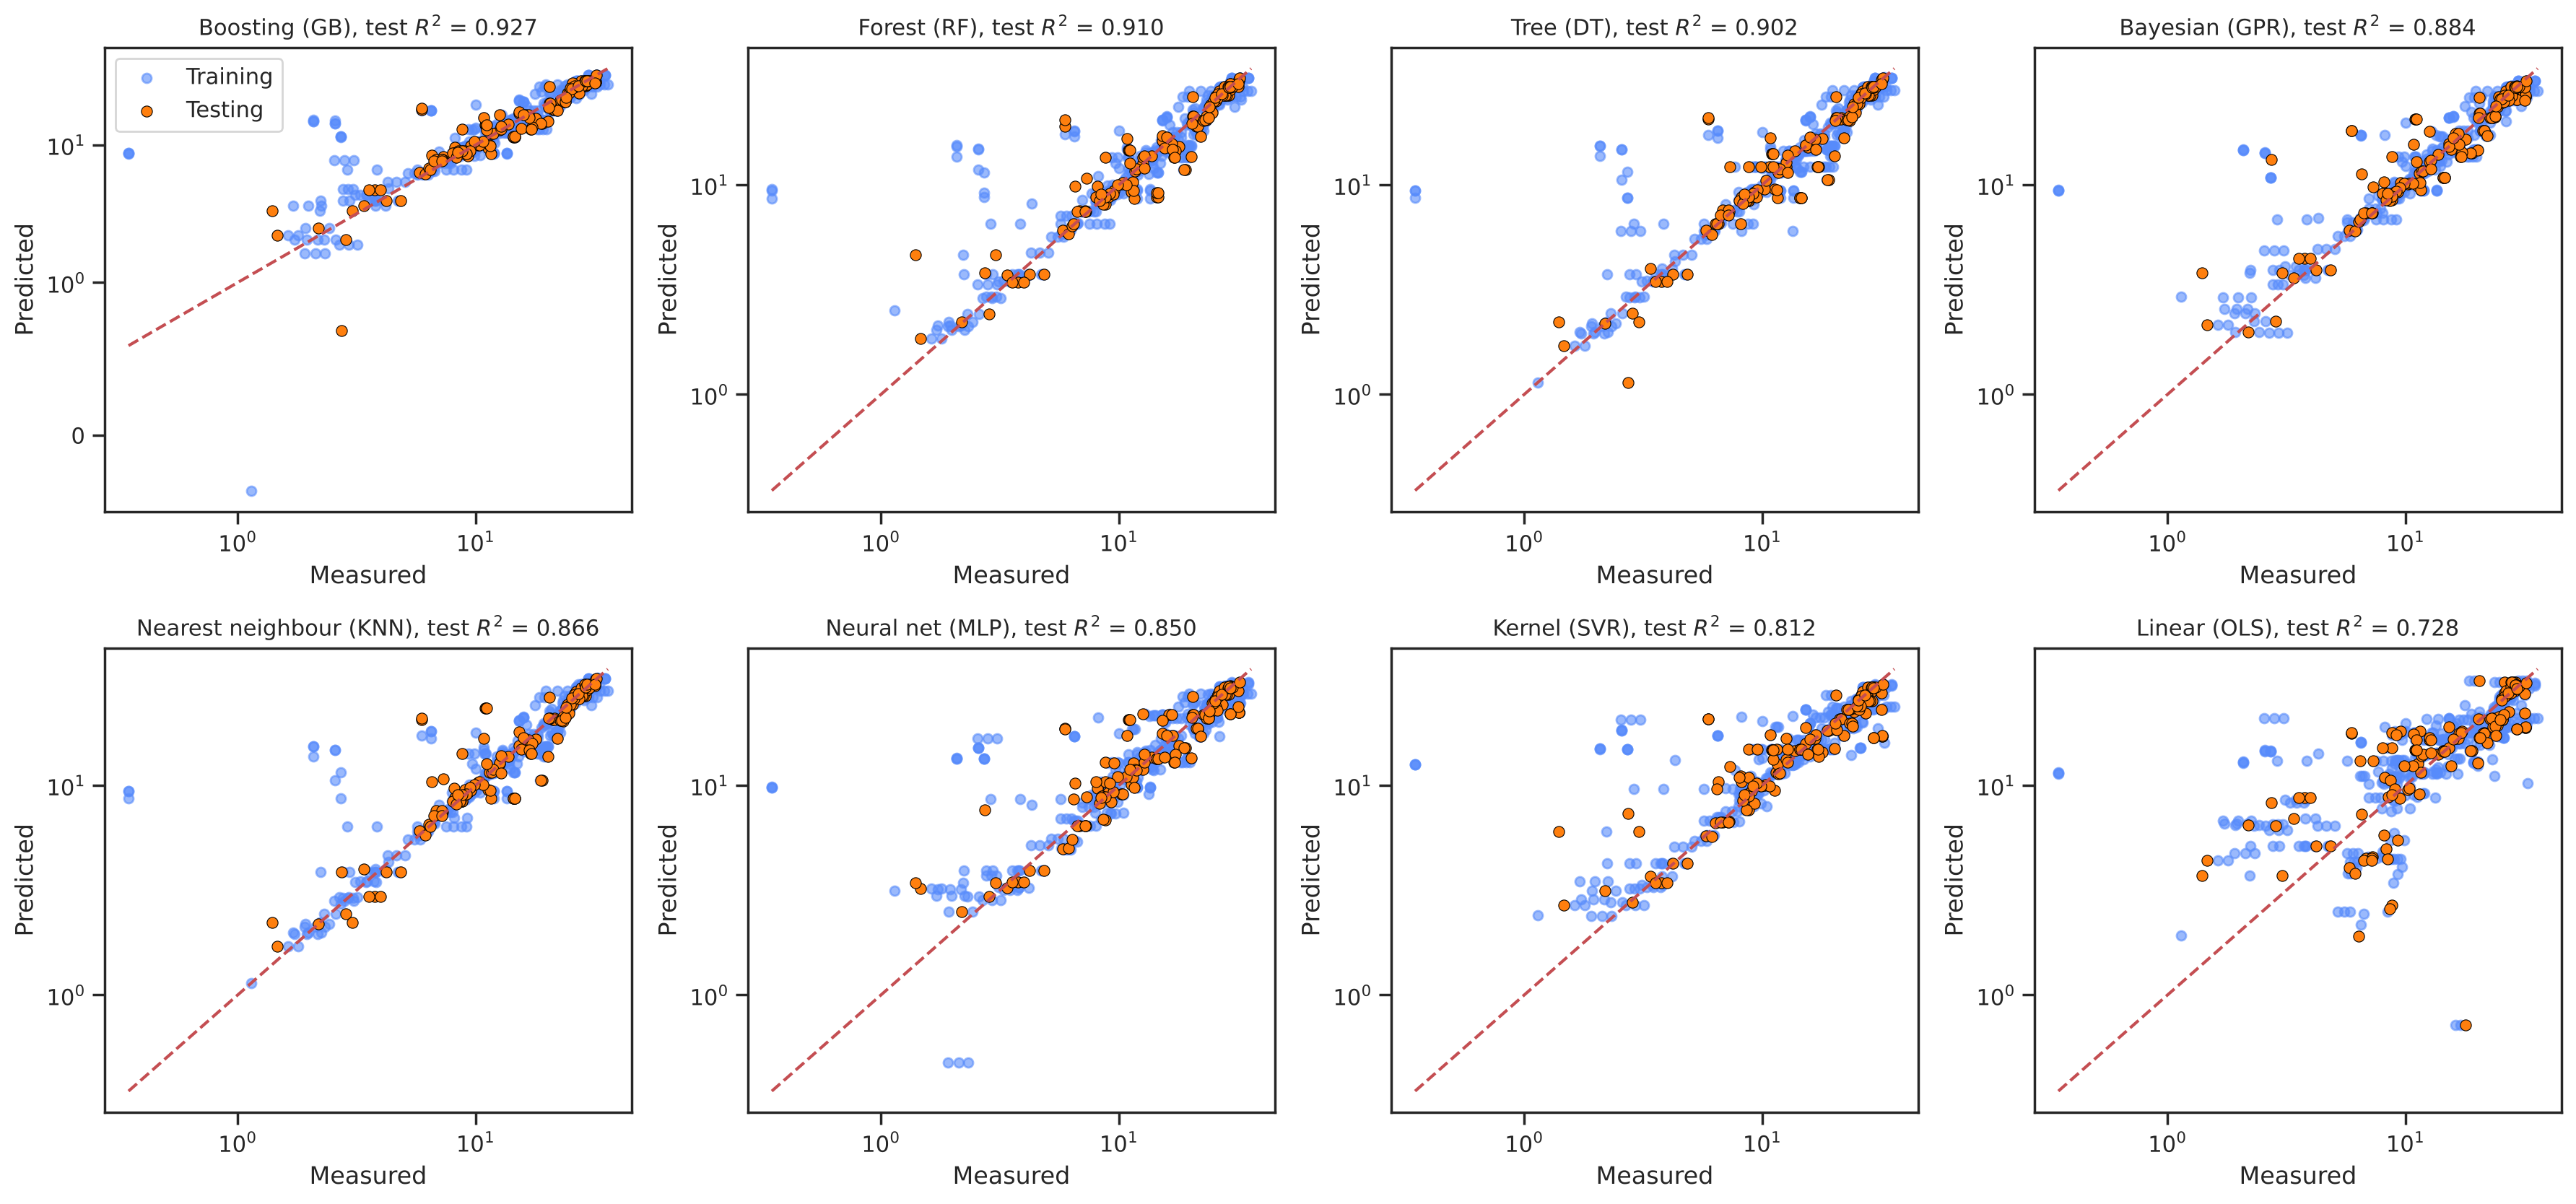

In [27]:
# best model of each family
best_per_family = results_df.loc[results_df.groupby('Family')['Test_r2'].idxmax()].sort_values('Test_r2', ascending=False)
log_axes = TASK.endswith('MaxLoad') or TASK.endswith('LSS')

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, (_, r) in zip(axes.ravel(), best_per_family.iterrows()):
    p = predictions[r.Model]
    ax.scatter(p['y_train'], p['pred_train'], s=22, color='#578BFB', alpha=0.6, label='Training')
    ax.scatter(p['y_test'], p['pred_test'], s=30, color='#ff7f0e', edgecolor='black', linewidth=0.4, label='Testing')
    lo = min(p['y_train'].min(), p['y_test'].min()); hi = max(p['y_train'].max(), p['y_test'].max())
    ax.plot([lo, hi], [lo, hi], 'r--', lw=1.5)
    if log_axes:
        ax.set_xscale('symlog', linthresh=1); ax.set_yscale('symlog', linthresh=1)
    ax.set_title(f"{r.Family} ({r.Model}), test $R^2$ = {r.Test_r2:.3f}", fontsize=11)
    ax.set_xlabel('Measured'); ax.set_ylabel('Predicted')
axes.ravel()[0].legend()
plt.tight_layout()
plt.show()

## Permutation Importance

In [28]:
importance = {}
for name, fitted_model in fitted.items():
    r = permutation_importance(fitted_model, X_test, y_test, scoring=SCORING, n_repeats=3, random_state=0, n_jobs=2)
    importance[name] = r.importances_mean
importance = pd.DataFrame(importance, index=X.columns)
importance.to_csv(f'{RESULTS}/{TASK}__permutation_importance.csv')
importance.mean(axis=1).sort_values(ascending=False).head(12)

Overlap_Length_mm                          0.361650
Adhesive_Thickness_mm                      0.354972
Aging_Days                                 0.075745
Surf_Plasma_corona                         0.065040
PostCure_Temp_C                            0.062417
Fillet                                     0.038326
Joint_Width_mm                             0.035131
Cure_Temp_C                                0.034285
Adhesive_Strength_MPa                      0.031528
Surf_Abrasion_sanding_grinding_brushing    0.031209
Filler1_wtpct                              0.028319
PostCure_Duration_h                        0.027698
dtype: float64

## SHAP Analysis

In [29]:
# best tree-based model of the task
tree_models = ['RF', 'ET', 'XGB', 'LGBM', 'CatBoost', 'DT'] + ([] if False else ['GB'])
test_scores = results_df.set_index('Model')['Test_r2']
best_tree = test_scores[test_scores.index.isin(tree_models)].idxmax()
print('SHAP model:', best_tree)

pipe_tree = fitted[best_tree]
X_scaled = pd.DataFrame(pipe_tree[:-1].transform(X), columns=X.columns)
explainer = shap.TreeExplainer(pipe_tree[-1])
shap_values = explainer.shap_values(X_scaled, check_additivity=False)
if isinstance(shap_values, list):
    shap_values = np.stack(shap_values, axis=-1)
shap_values = np.asarray(shap_values)

# mean absolute SHAP value (averaged over classes for the classifiers)
abs_shap = np.abs(shap_values).mean(axis=tuple(i for i in range(shap_values.ndim) if i != 1))
importance_df = pd.DataFrame({'Feature': X.columns, 'Mean_Abs_SHAP': abs_shap}).sort_values('Mean_Abs_SHAP', ascending=False)
importance_df.to_csv(f'{RESULTS}/{TASK}__shap_importance.csv', index=False)
importance_df.head(12)

SHAP model: GB


,Feature,Mean_Abs_SHAP
15,Adhesive_Thickness_mm,4.554858
13,Overlap_Length_mm,2.573964
23,Aging_Days,1.281536
32,Fillet,1.187110
16,Cure_Temp_C,0.703815
7,Filler1_wtpct,0.641414
17,Cure_Duration_h,0.561048
10,Adhesive_Modulus_GPa,0.475684
29,Filler1_Type,0.475427
22,Humidity_pctRH,0.403589


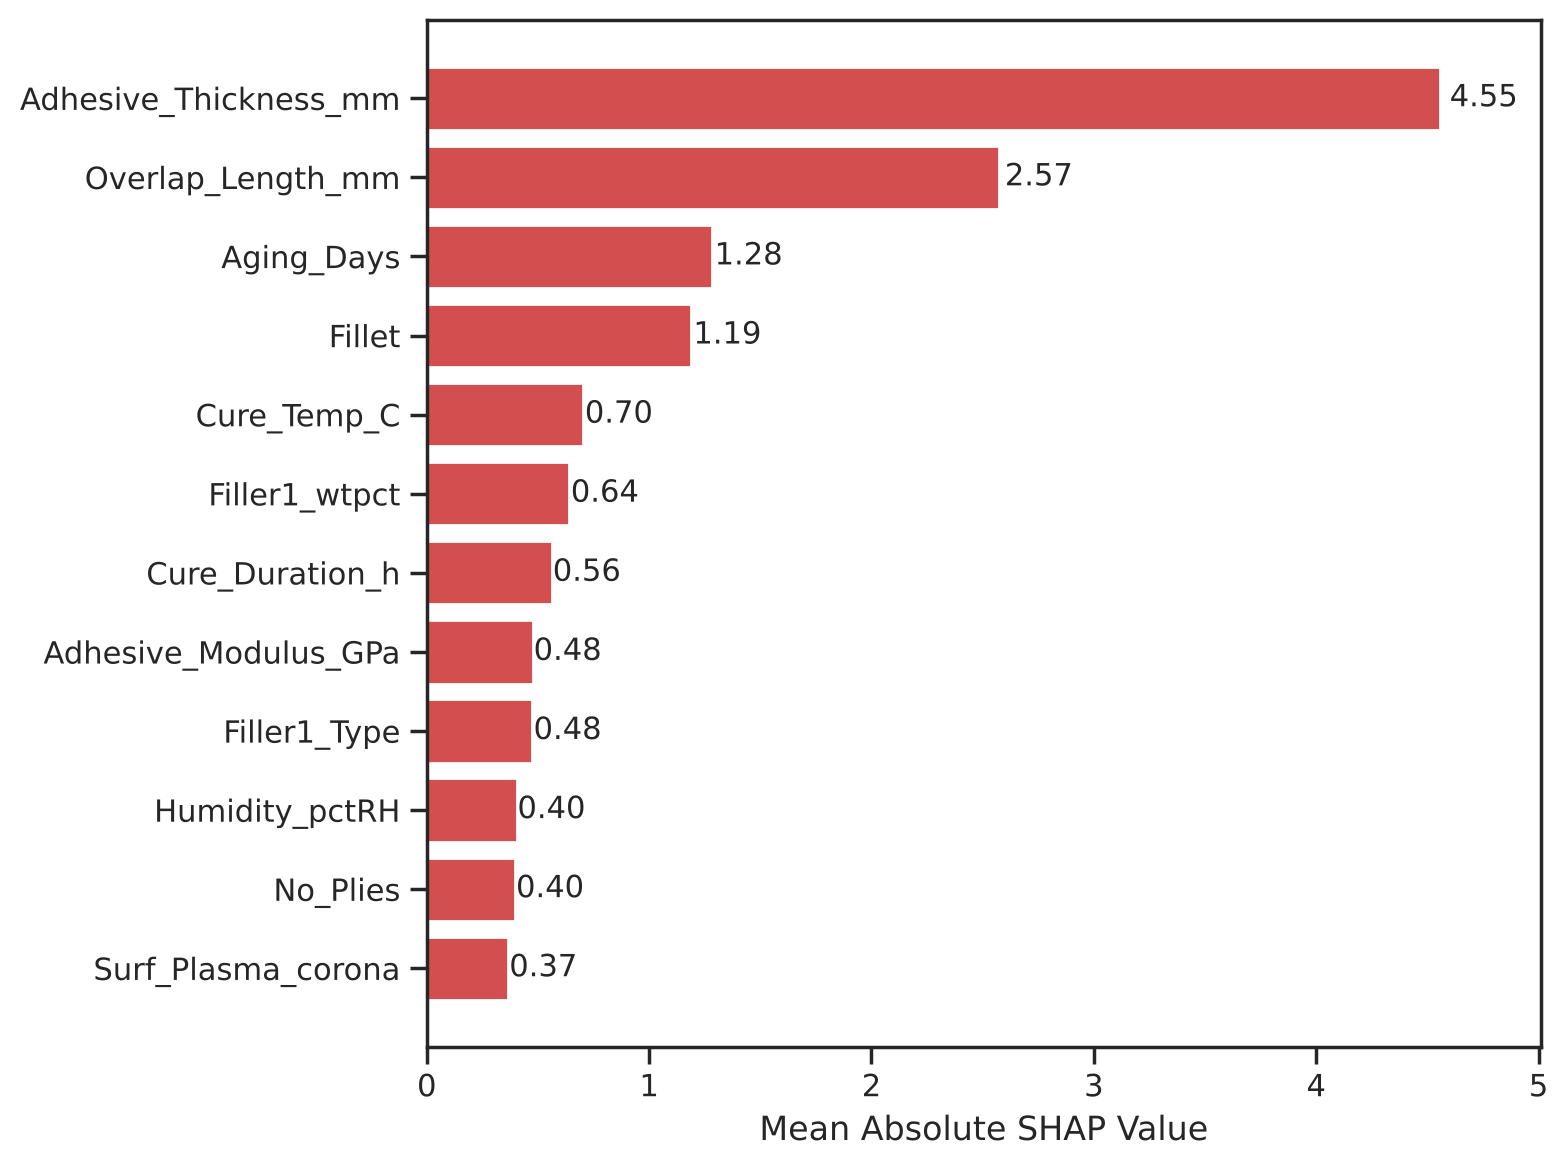

In [30]:
# Horizontal bar plot for feature importance with value labels
plt.figure(figsize=(8, 6))
top_features = importance_df.head(12).iloc[::-1]
bars = plt.barh(top_features['Feature'], top_features['Mean_Abs_SHAP'], color='#d34f4f')
for bar in bars:
    width = bar.get_width()
    plt.text(width * 1.01, bar.get_y() + bar.get_height() / 2, f'{width:.2f}', ha='left', va='center', fontsize=11)
plt.xlabel('Mean Absolute SHAP Value')
plt.margins(x=0.1)
plt.tight_layout()
plt.show()

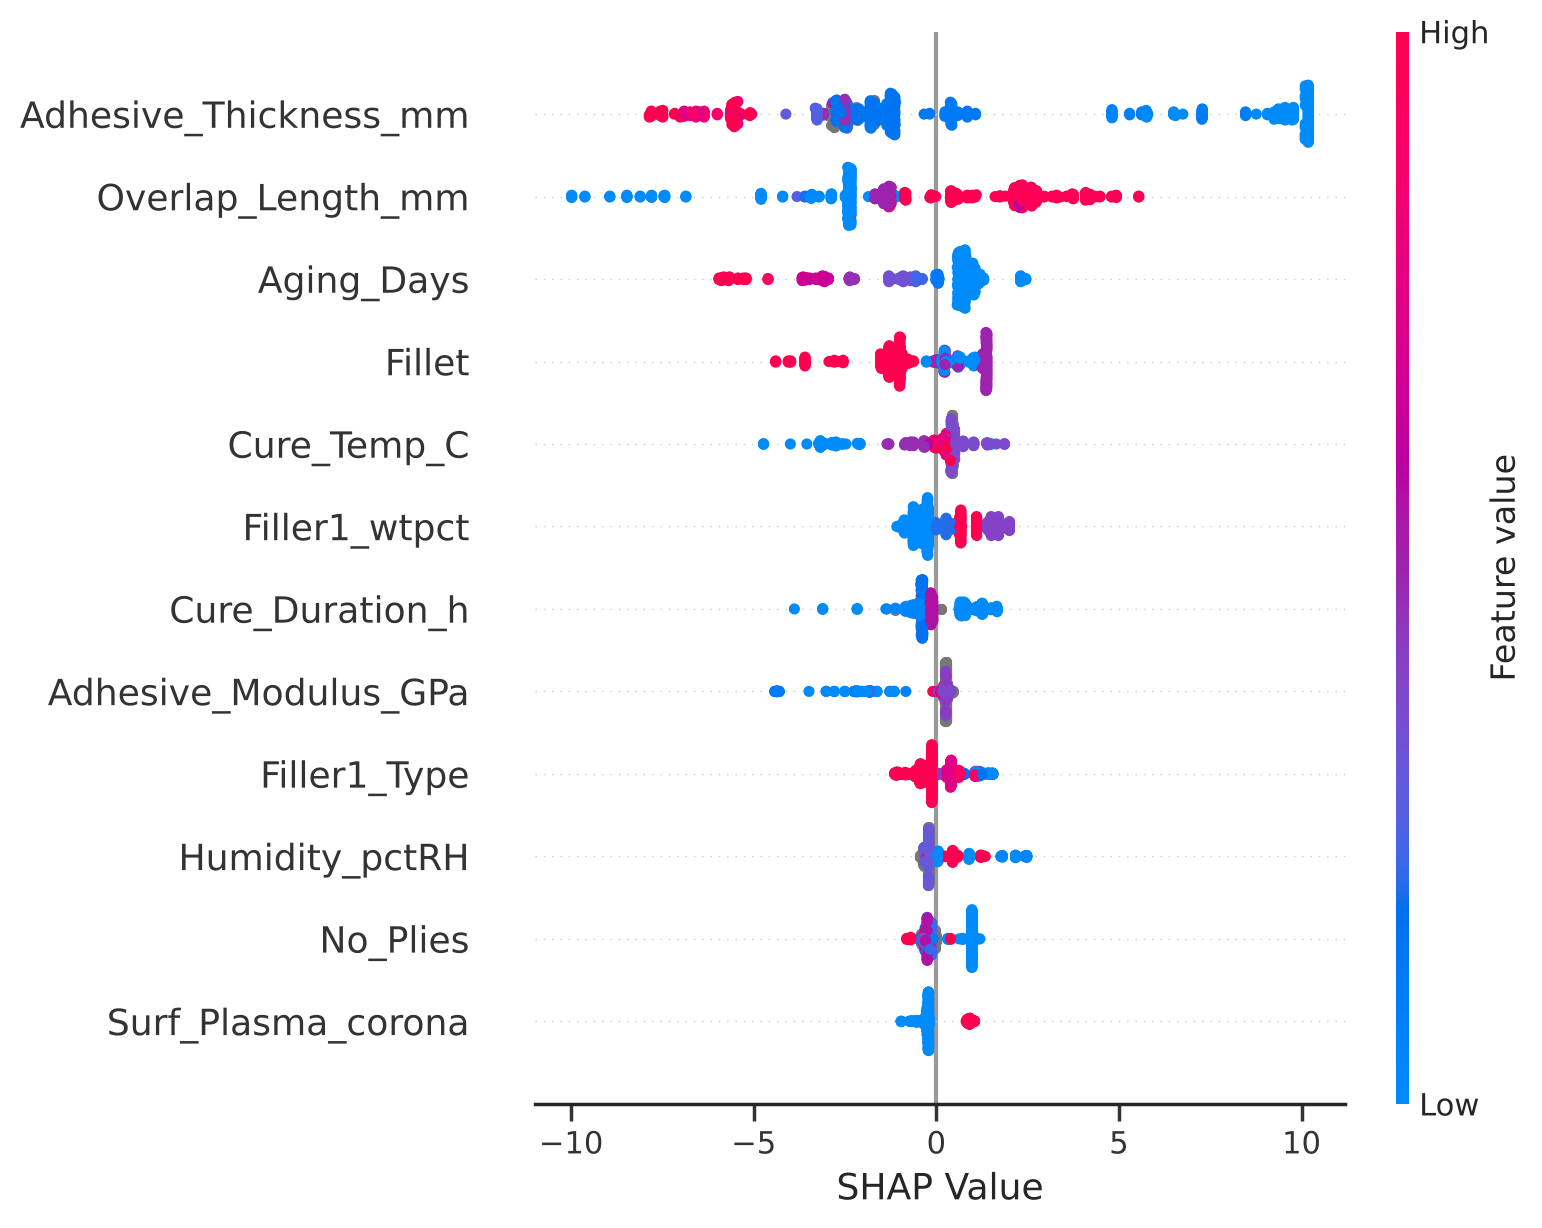

In [31]:
# Beeswarm plot for overall feature importance
plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X, max_display=12, show=False)
plt.xlabel('SHAP Value')
plt.tight_layout()
plt.show()

## SHAP Interaction Values

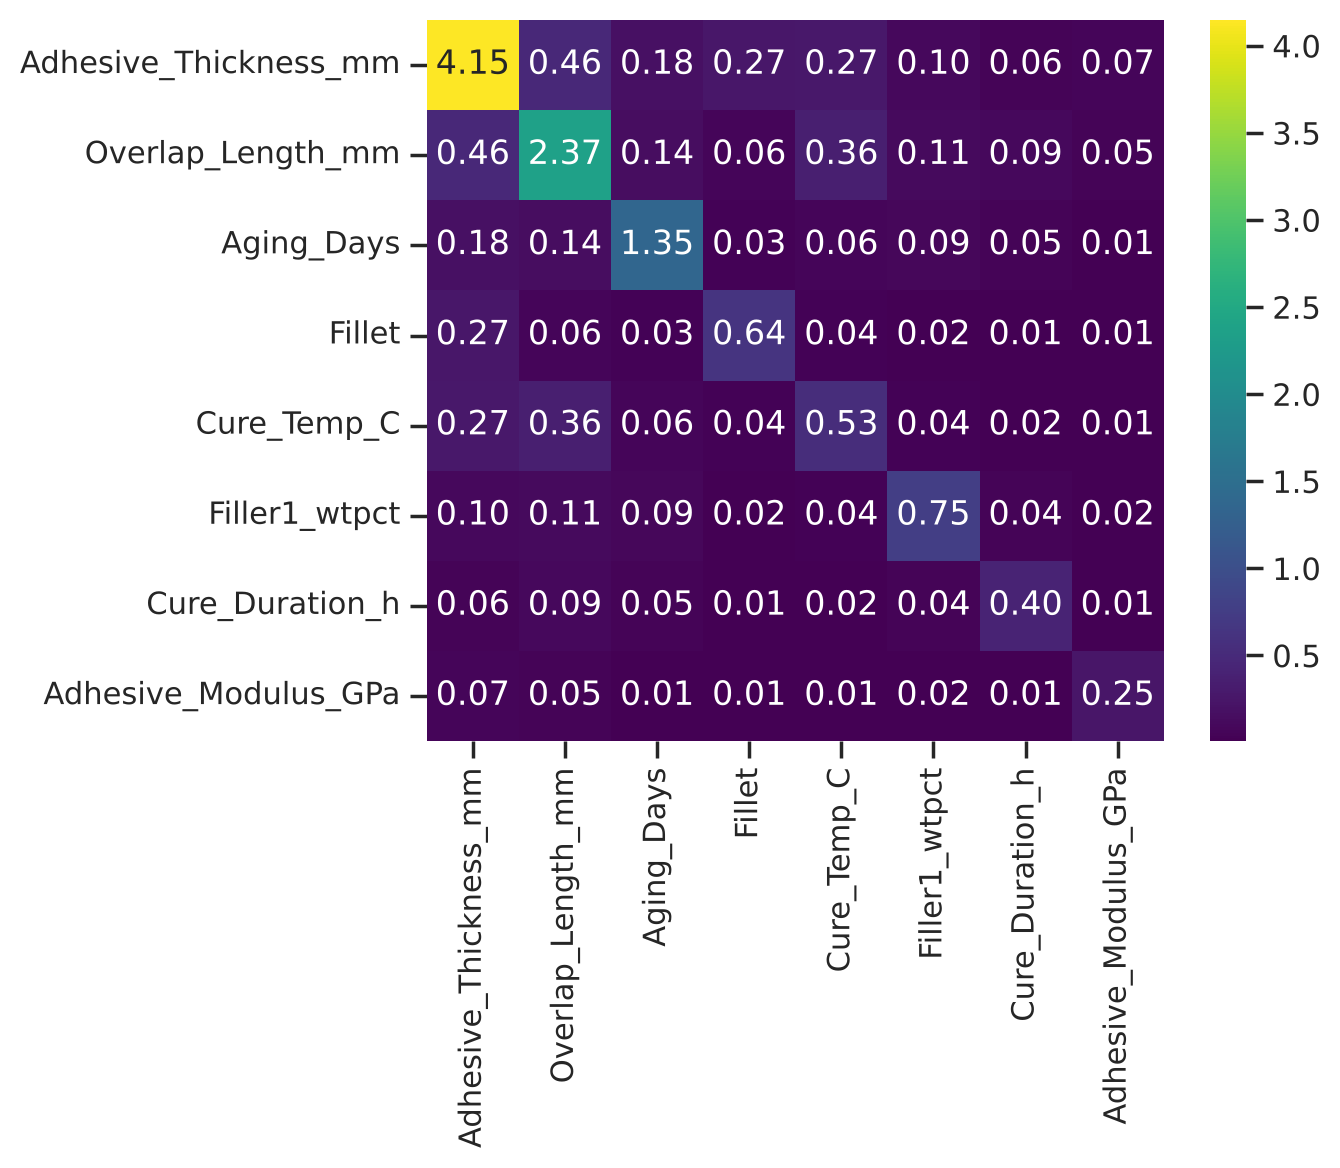

In [32]:
# XGBoost on a random subset of 300 records
xgb_pipe = fitted['XGB']
X_xgb = pd.DataFrame(xgb_pipe[:-1].transform(X), columns=X.columns)
subset = np.random.RandomState(0).choice(len(X), size=min(300, len(X)), replace=False)
interaction = shap.TreeExplainer(xgb_pipe[-1]).shap_interaction_values(X_xgb.iloc[subset])
interaction_mean = pd.DataFrame(np.abs(interaction).mean(0), index=X.columns, columns=X.columns)
top = importance_df['Feature'].head(8).tolist()
plt.figure(figsize=(7, 6))
sns.heatmap(interaction_mean.loc[top, top], cmap='viridis', annot=True, fmt='.2f')
plt.tight_layout()
plt.show()

## Partial Dependence

In [33]:
# one representative model per family, the four most important continuous inputs
reps = results_df.loc[results_df.groupby('Family')['Test_r2'].idxmax()].set_index('Family')['Model'].to_dict()
pi = importance.clip(lower=0)
good = [m for m in pi.columns if test_scores[m] > 0.5]
consensus = (pi[good] / pi[good].sum()).mean(axis=1)
continuous = [c for c in X.columns if X[c].nunique() > 8]
top_inputs = consensus[consensus.index.isin(continuous)].sort_values(ascending=False).index[:4].tolist()
print(top_inputs)

rows = np.random.RandomState(1).choice(len(X), size=min(200, len(X)), replace=False)
X_sample = X.iloc[rows]
pdp = {}
for feature in top_inputs:
    grid_values = np.unique(np.quantile(X[feature].dropna(), np.linspace(0.02, 0.98, 25)))
    curves = {}
    for family, name in reps.items():
        curve = []
        for v in grid_values:
            X_tmp = X_sample.copy()
            X_tmp[feature] = v
            curve.append(float(np.mean(fitted[name].predict(X_tmp))))
        curves[family] = (name, np.array(curve))
    pdp[feature] = dict(grid=grid_values, curves=curves)

['Overlap_Length_mm', 'Adhesive_Thickness_mm', 'Aging_Days', 'Cure_Temp_C']


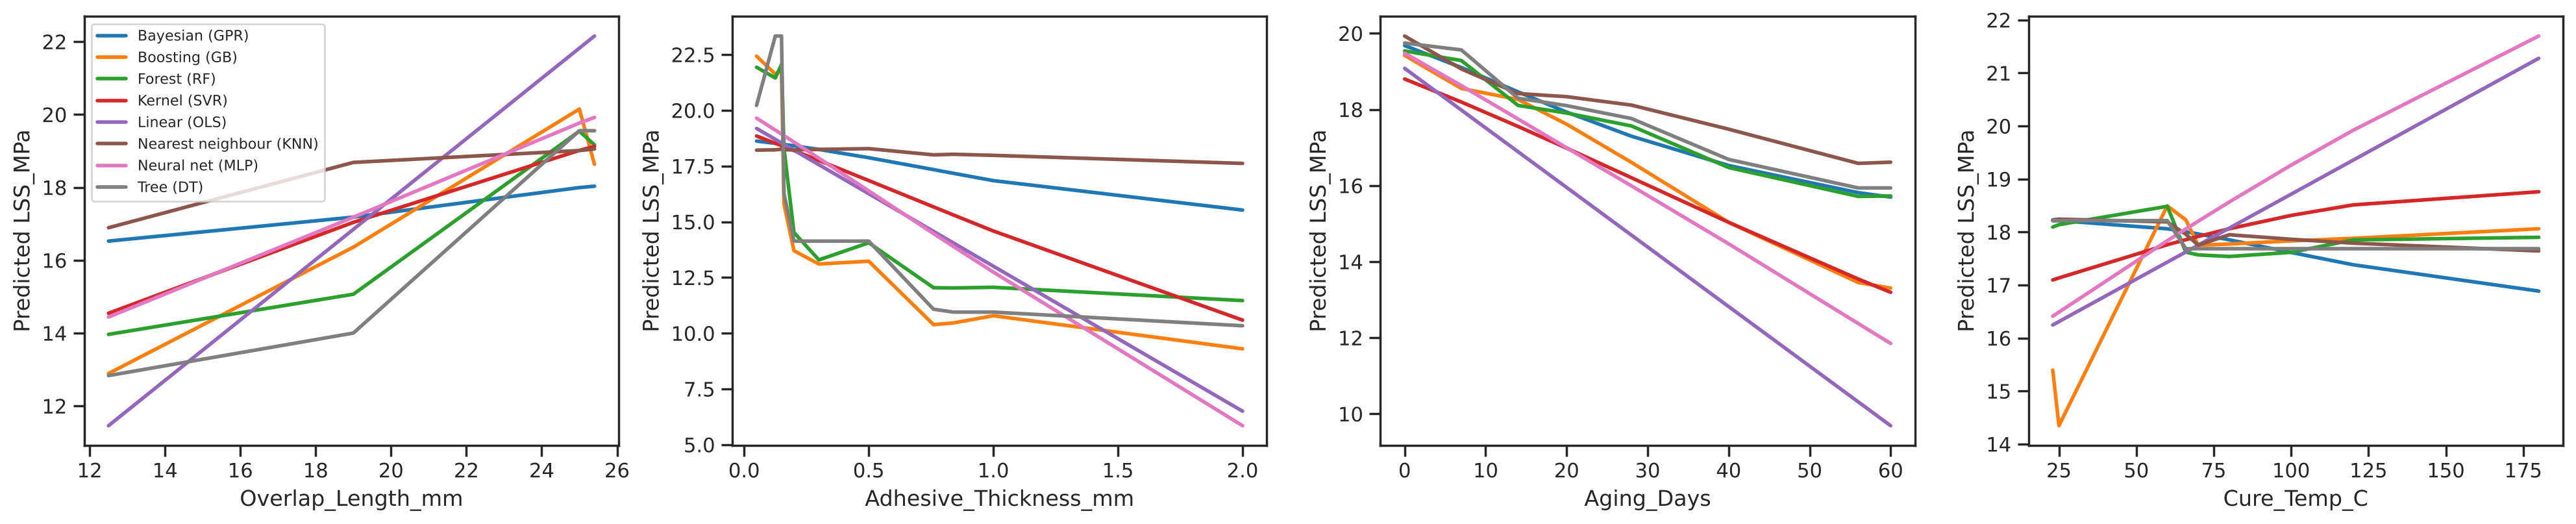

In [34]:
palette = dict(zip(sorted(reps), sns.color_palette('tab10', len(reps))))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, feature in zip(axes, top_inputs):
    for family, (name, curve) in pdp[feature]['curves'].items():
        ax.plot(pdp[feature]['grid'], curve, color=palette[family], lw=2, label=f'{family} ({name})')
    ax.set_xlabel(feature)
    ax.set_ylabel('Predicted ' + target)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Save

In [35]:
with open(f'{RESULTS}/{TASK}__predictions.pkl', 'wb') as fh:
    pickle.dump(predictions, fh)
np.save(f'{RESULTS}/{TASK}__shap_values.npy', shap_values)
with open(f'{RESULTS}/{TASK}__pdp.pkl', 'wb') as fh:
    pickle.dump(pdp, fh)